# Demo pipeline (María): anomalías en logs LLM sin verdad conocida

Parte de `demo_pipeline_adrian.ipynb` (misma lectura de HANA y mismas ventanas de `ventanas.py`) y cambia **lo que ocurre después de generar las ventanas**. Solo cubre LLM; system se puede tratar igual cambiando la lista de features.

**Requisitos:** el dataset crudo ya está en HANA, el `.env` tiene las credenciales y `ventanas.py` y `anomalias_llm.py` están en esta carpeta. Las tablas que crea son temporales (`#...`) y desaparecen al cerrar la sesión.

| Limitante del demo de Adrian | Qué hace este notebook |
|---|---|
| `contamination=0.01` obliga a marcar siempre el 1 % de las ventanas | El umbral sale de la distribución del score (mediana + k·MAD) y se muestra cuántas ventanas se marcan según k |
| Un modelo por semana, entrenado y puntuado con los mismos datos | Un solo modelo con todo el periodo, 5 semillas promediadas y una prueba fuera de muestra (entrena la semana 0, puntúa el resto) |
| Una sola semilla: no se sabe si el resultado es estable | Estabilidad del ranking entre semillas (Jaccard y Spearman) |
| Sin verdad conocida no hay precisión | **Inyección sintética** de anomalías de magnitud conocida: mide qué tan grande debe ser un cambio para que se detecte |
| Un único modelo decide | Consenso con dos detectores independientes (Mahalanobis robusta y z univariado) |
| El ciclo diario se ignora | Línea base por hora del día para las features con estacionalidad fuerte (se decide con η²) |
| El score no explica nada | Por ventana: qué features se desvían, hacia dónde y cuánto. Por evento: tema, nivel de confianza y lectura de negocio |

## 0. Parámetros y conexión

In [2]:
import os, time, importlib
from pathlib import Path
from dotenv import load_dotenv
import hana_ml.dataframe as dataframe
from hana_ml.dataframe import create_dataframe_from_pandas
from hana_ml.algorithms.pal.preprocessing import IsolationForest
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
import ventanas
import anomalias_llm as al

importlib.reload(ventanas)
importlib.reload(al)

# --- Datos ---
TABLA = 'LOGS_2026_10'          # tabla cruda en HANA
WEEK_DAYS, MIN_LAST_DAYS = 7, 3 # misma partición semanal que el demo de Adrian

# --- Modelo ---
SEMILLAS = [11, 42, 73, 101, 2026]   # el score final es el promedio de estas semillas
N_ARBOLES, MAX_SAMPLES = 250, 256

# --- Umbrales y consenso ---
K_UMBRAL = 3.5        # mediana + K·MAD del score. Más alto = más estricto
Z_UNI = 4.5           # desviación (en σ robustas) a partir de la cual una sola feature marca la ventana
ETA2_MIN = 0.10       # una feature se ajusta por hora del día si la hora explica >= 10 % de su varianza
MAX_GAP_MIN = 7.5     # ventanas marcadas a <= 7.5 min forman un solo evento

# --- Validación por inyección sintética ---
MAGNITUDES = (2, 3, 4, 6, 8)   # tamaño del cambio, en σ robustas
N_POR_CELDA = 30               # ventanas inyectadas por (escenario, magnitud)
OBJETIVO_RECALL = 0.8          # "se detecta" = al menos 80 % de las inyecciones

FEATURES_LLM = [
    'TOTAL_LLM_REQUESTS', 'AVG_LLM_COST_USD', 'RATIO_INJECTION', 'AVG_TOKEN_RATIO',
    'AVG_RESPONSE_TIME_MS', 'LLM_ERROR_RATE', 'LLM_TIMEOUT_RATE', 'TEMPERATURE_VARIANCE',
    'PROMPT_CATEGORY_ENTROPY', 'STREAM_RATIO', 'AVG_PROMPT_LENGTH', 'MAX_PROMPT_LENGTH',
]

# --- Estilo de gráficos (paleta de referencia: azul = serie, naranja = anomalía) ---
AZUL, NARANJA, TINTA, TINTA2, GRIS, FONDO = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#d9d8d3', '#fcfcfb'
CMAP_SEC = LinearSegmentedColormap.from_list('sec', ['#cde2fb', '#3987e5', '#0d366b'])
CMAP_DIV = LinearSegmentedColormap.from_list('div', ['#2a78d6', '#f0efec', '#e34948'])

def estilo(ax, titulo, xlabel='', ylabel=''):
    ax.set_title(titulo, loc='left', fontsize=12, color=TINTA)
    ax.set_xlabel(xlabel, color=TINTA2); ax.set_ylabel(ylabel, color=TINTA2)
    ax.set_facecolor(FONDO); ax.grid(axis='y', color=GRIS, lw=0.6); ax.set_axisbelow(True)
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
    for s in ('left', 'bottom'): ax.spines[s].set_color(GRIS)
    ax.tick_params(colors=TINTA2)

In [3]:
load_dotenv()
conn = dataframe.ConnectionContext(address=os.getenv('HANA_ADDRESS'),
                                   port=int(os.getenv('HANA_PORT')),
                                   user=os.getenv('HANA_USER'),
                                   password=os.getenv('HANA_PASSWORD'))
conn.connection.isconnected()

True

## 1. Lectura y partición semanal (igual que el demo de Adrian)

In [4]:
dataset = conn.table(TABLA).drop(['_IGNORED'])
cols_drop_llm = ['HTTP_STATUS_CODE', 'SERVICE_ID', 'CLIENT_IP']
df_llm = dataset.filter("\"_INDEX\" LIKE 'llm-logs%'").drop(cols_drop_llm)
print('Columnas LLM:', len(df_llm.columns))

Columnas LLM: 40


In [5]:
TS_EXPR = ("TO_TIMESTAMP(REPLACE(REPLACE(\"TIMESTAMP\",'T',' '),'Z',''), "
           "'YYYY-MM-DD HH24:MI:SS.FF3')")

r = conn.sql(f'SELECT MIN({TS_EXPR}) AS T0, MAX({TS_EXPR}) AS TMAX FROM {TABLA}').collect()
t0, t_max = pd.to_datetime(r.loc[0, 'T0']), pd.to_datetime(r.loc[0, 'TMAX'])

span = t_max - t0
n_full = span // pd.Timedelta(days=WEEK_DAYS)
rest = span - n_full * pd.Timedelta(days=WEEK_DAYS)
n_weeks = n_full + (1 if rest >= pd.Timedelta(days=MIN_LAST_DAYS) else 0)

t0_sql = t0.strftime('%Y-%m-%d %H:%M:%S')
week_expr = (f"FLOOR(SECONDS_BETWEEN(TO_TIMESTAMP('{t0_sql}','YYYY-MM-DD HH24:MI:SS'), "
             f"{TS_EXPR}) / {WEEK_DAYS * 86400})")

df_llm = df_llm.select('*', (week_expr, 'WEEK_IDX'))
llm_weeks = {w: df_llm.filter(f'WEEK_IDX = {w}') for w in range(n_weeks)}
print(f't0={t0}  t_max={t_max}  n_weeks={n_weeks}')
print('llm:', {w: d.count() for w, d in llm_weeks.items()})

t0=2026-10-01 00:00:00  t_max=2026-10-11 23:59:59  n_weeks=2
llm: {0: 959153, 1: 538547}


## 2. Ventanas LLM
Se generan por semana con `ventanas.build_llm_windows` (ventanas de 5 min, paso de 2.5 min, solo ventanas completas) y se juntan en una sola tabla. Las ventanas que cruzarían el corte entre semanas se pierden, como en el demo de Adrian.

`WID` es la clave entera que pide PAL y es también el índice de todas las tablas de este notebook.

In [6]:
def ventanas_semana(w):
    win = ventanas.materialize(conn, ventanas.build_llm_windows(conn, llm_weeks[w]), '#WIN_LLM')
    d = win.collect().drop(columns=['WINDOW_INDEX'])
    d.insert(0, 'WEEK', w)
    return d

win = pd.concat([ventanas_semana(w) for w in range(n_weeks)], ignore_index=True)
win['WINDOW_START'] = pd.to_datetime(win['WINDOW_START'])
win = win.sort_values('WINDOW_START').reset_index(drop=True)
win['WID'] = np.arange(1, len(win) + 1)
win = win.set_index('WID', drop=False)
print(win.shape, '|', win['WINDOW_START'].min(), '->', win['WINDOW_START'].max())
win.head()

(6334, 15) | 2026-10-01 00:00:00 -> 2026-10-11 23:55:00


,WEEK,WINDOW_START,TOTAL_LLM_REQUESTS,AVG_LLM_COST_USD,RATIO_INJECTION,AVG_TOKEN_RATIO,AVG_RESPONSE_TIME_MS,LLM_ERROR_RATE,LLM_TIMEOUT_RATE,TEMPERATURE_VARIANCE,PROMPT_CATEGORY_ENTROPY,STREAM_RATIO,AVG_PROMPT_LENGTH,MAX_PROMPT_LENGTH,WID
WID,,,,,,,,,,,,,,,
1,0,2026-10-01 00:00:00,472.0,0.016063,0.000000,1.455021,9036.169301,0.186441,0.103814,0.182399,0.971443,0.0,112.635593,181.0,1
2,0,2026-10-01 00:02:30,428.0,0.016515,0.002336,1.378325,9225.218738,0.172897,0.109813,0.183961,0.972997,0.0,112.210280,171.0,2
3,0,2026-10-01 00:05:00,443.0,0.015859,0.002257,1.328618,9517.730542,0.173815,0.119639,0.190125,0.974160,0.0,110.952595,171.0,3
4,0,2026-10-01 00:07:30,465.0,0.016600,0.002151,1.283058,9203.515570,0.172043,0.109677,0.195581,0.958232,0.0,110.002150,172.0,4
5,0,2026-10-01 00:10:00,458.0,0.015720,0.004367,1.424112,8681.368079,0.185590,0.087336,0.187754,0.956930,0.0,111.648471,174.0,5


## 3. Diagnóstico de las ventanas y línea base robusta
Antes de modelar conviene saber con qué se trabaja:
- **Nulos:** se rellenan con la mediana (p. ej. `TEMPERATURE_VARIANCE` es nulo si la ventana tiene un solo log con temperatura).
- **Correlaciones altas:** dos features casi iguales cuentan dos veces la misma señal.
- **η² por hora:** qué parte de la varianza de cada feature la explica la hora del día. Si es alta, una ventana a las 14:00 se compara contra las 14:00 de los demás días, no contra todo el periodo.

In [7]:
win, nulos = al.limpiar_features(win, FEATURES_LLM)
print('Nulos rellenados con la mediana:', dict(nulos) if len(nulos) else 'ninguno')
display(win[FEATURES_LLM].describe().T.round(4))

corr = al.pares_correlacionados(win, FEATURES_LLM, 0.9)
print('\nPares con |correlación| >= 0.9:', 'ninguno' if corr.empty else '')
if not corr.empty: display(corr)

eta2 = al.eta2_hora(win, FEATURES_LLM)
display(eta2.round(3).to_frame('eta2_hora'))

Nulos rellenados con la mediana: ninguno


,count,mean,std,min,25%,50%,75%,max
TOTAL_LLM_REQUESTS,6334.0,472.7589,28.9872,377.0000,452.0000,473.0000,494.0000,574.0000
AVG_LLM_COST_USD,6334.0,0.0163,0.0010,0.0127,0.0156,0.0163,0.0170,0.0202
RATIO_INJECTION,6334.0,0.0018,0.0020,0.0000,0.0000,0.0020,0.0023,0.0141
AVG_TOKEN_RATIO,6334.0,1.4506,0.1104,1.0790,1.3761,1.4459,1.5204,1.9175
AVG_RESPONSE_TIME_MS,6334.0,8784.0383,407.4363,7417.5760,8506.3731,8777.0901,9054.2020,10983.8914
LLM_ERROR_RATE,6334.0,0.2003,0.0185,0.1366,0.1877,0.2004,0.2128,0.2714
LLM_TIMEOUT_RATE,6334.0,0.0998,0.0139,0.0566,0.0903,0.0995,0.1088,0.1632
TEMPERATURE_VARIANCE,6334.0,0.1875,0.0078,0.1580,0.1822,0.1874,0.1928,0.2201
PROMPT_CATEGORY_ENTROPY,6334.0,0.9707,0.0071,0.9391,0.9663,0.9712,0.9757,0.9908
STREAM_RATIO,6334.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000



Pares con |correlación| >= 0.9: ninguno


,eta2_hora
MAX_PROMPT_LENGTH,0.013
RATIO_INJECTION,0.010
AVG_TOKEN_RATIO,0.009
LLM_ERROR_RATE,0.007
AVG_PROMPT_LENGTH,0.007
LLM_TIMEOUT_RATE,0.006
AVG_RESPONSE_TIME_MS,0.006
TEMPERATURE_VARIANCE,0.005
PROMPT_CATEGORY_ENTROPY,0.005
AVG_LLM_COST_USD,0.005


In [8]:
ESTACIONALES = list(eta2[eta2 >= ETA2_MIN].index)
print('Features ajustadas por hora del día:', ESTACIONALES or 'ninguna (sin ciclo diario relevante)')

params = al.ajustar_linea_base(win, FEATURES_LLM, ESTACIONALES)
Z, C = al.aplicar_linea_base(win, params)      # Z: desviación robusta (σ) | C: valor típico
ZCOLS = ['Z_' + f for f in FEATURES_LLM]
display(Z.describe().T[['mean', '50%', 'std', 'min', 'max']].round(2))

Features ajustadas por hora del día: ninguna (sin ciclo diario relevante)


,mean,50%,std,min,max
TOTAL_LLM_REQUESTS,-0.01,0.0,0.93,-3.08,3.24
AVG_LLM_COST_USD,0.03,-0.0,1.00,-3.54,3.84
RATIO_INJECTION,-0.06,0.0,0.67,-0.67,4.05
AVG_TOKEN_RATIO,0.04,0.0,1.04,-3.44,4.42
AVG_RESPONSE_TIME_MS,0.02,0.0,1.00,-3.35,5.43
LLM_ERROR_RATE,-0.01,0.0,1.00,-3.44,3.82
LLM_TIMEOUT_RATE,0.01,0.0,1.02,-3.14,4.66
TEMPERATURE_VARIANCE,0.02,0.0,1.00,-3.75,4.18
PROMPT_CATEGORY_ENTROPY,-0.07,0.0,1.02,-4.59,2.82
STREAM_RATIO,0.00,0.0,0.00,0.00,0.00


## 4. Isolation Forest (ensamble de semillas)
- El modelo se entrena con **las desviaciones robustas (z)** de cada feature, no con los valores crudos. Así las features con ciclo diario ya vienen corregidas por hora.
- Se entrena **un modelo por semilla** y el score final es el promedio, para que no dependa del azar de una sola.
- `LABEL` y `contamination` **no se usan**: solo se toma `SCORE`, y el umbral se decide después con los datos.
- En la misma pasada se puntúan las **ventanas inyectadas** (sección 7), que el modelo nunca vio al entrenar.

In [9]:
X = Z.set_axis(ZCOLS, axis=1)
z_h = create_dataframe_from_pandas(conn, pd.concat([win[['WID', 'WEEK']], X], axis=1),
                                   '#MARIA_LLM_Z', force=True, disable_progressbar=True)

# Anomalías sintéticas de magnitud conocida, sobre copias de ventanas reales
ESCENARIOS = al.escenarios_por_defecto(FEATURES_LLM)
inj = al.inyectar(win, params, ESCENARIOS, MAGNITUDES, N_POR_CELDA, semilla=7).set_index('_KEY', drop=False)
Zi, Ci = al.aplicar_linea_base(inj, params)
inj_h = create_dataframe_from_pandas(
    conn, pd.concat([inj[['_KEY']].rename(columns={'_KEY': 'WID'}), Zi.set_axis(ZCOLS, axis=1)], axis=1),
    '#MARIA_LLM_INJ', force=True, disable_progressbar=True)
print(len(win), 'ventanas reales |', len(inj), 'ventanas inyectadas |', len(ESCENARIOS), 'escenarios')

6334 ventanas reales | 2250 ventanas inyectadas | 15 escenarios


In [10]:
def entrenar_y_puntuar(semilla, entrenamiento, objetivos):
    # Entrena con `entrenamiento` y devuelve el SCORE de cada tabla de `objetivos`, indexado por WID.
    m = IsolationForest(n_estimators=N_ARBOLES, max_samples=MAX_SAMPLES, random_state=semilla)
    m.fit(data=entrenamiento, key='WID', features=ZCOLS)
    salida = []
    for h in objetivos:
        d = m.predict(data=h, key='WID', features=ZCOLS, show_explainer=False).collect()
        salida.append(d.set_index(d.columns[0])['SCORE'])
    return salida

sc_real, sc_inj = {}, {}
for s in SEMILLAS:
    t_ini = time.time()
    sc_real[s], sc_inj[s] = entrenar_y_puntuar(s, z_h, [z_h, inj_h])
    print(f'semilla {s}: {time.time() - t_ini:.1f} s')

scores = pd.DataFrame(sc_real).reindex(win.index)         # ventanas x semillas
score = scores.mean(axis=1)                                # score final
score_inj = pd.DataFrame(sc_inj).reindex(inj.index).mean(axis=1)

semilla 11: 3.2 s
semilla 42: 2.5 s
semilla 73: 2.6 s
semilla 101: 2.6 s
semilla 2026: 2.5 s


In [11]:
# Prueba fuera de muestra: se entrena SOLO con la semana 0 y se puntúa todo.
# Si el ranking de las semanas siguientes coincide con el del modelo completo, el resultado no depende
# de haber entrenado y puntuado con los mismos datos.
if n_weeks > 1:
    z_w0 = z_h.filter('WEEK = 0')
    s_oos = entrenar_y_puntuar(SEMILLAS[0], z_w0, [z_h])[0].reindex(win.index)
    resto = win['WEEK'] > 0
    k_oos = max(10, int(round(0.01 * resto.sum())))
    top_oos = set(s_oos[resto].nlargest(k_oos).index)
    top_ens = set(score[resto].nlargest(k_oos).index)
    print(f'Semanas 1+ ({resto.sum()} ventanas): Spearman entre modelo fuera de muestra y ensamble = '
          f"{s_oos[resto].corr(score[resto], method='spearman'):.3f}")
    print(f'Coincidencia del top-{k_oos}: {len(top_oos & top_ens) / len(top_oos | top_ens):.2f} (Jaccard)')
else:
    print('Solo hay una semana: no se puede hacer la prueba fuera de muestra.')

Semanas 1+ (2303 ventanas): Spearman entre modelo fuera de muestra y ensamble = 0.949
Coincidencia del top-23: 0.64 (Jaccard)


## 5. ¿El resultado es estable?
Si cambiar la semilla cambia mucho qué ventanas salen arriba, el ranking es azar. Se mide con el Jaccard de los top-k de cada par de semillas y con la correlación de Spearman de sus scores. Como referencia: el Spearman suele ser alto (el grueso de las ventanas es parecido), pero el Jaccard del top es más exigente porque compara justo las colas.

In [12]:
K_TOP = max(10, int(round(0.01 * len(win))))
est = al.estabilidad(scores, K_TOP)
print(f"Top-{K_TOP} por semilla -> Jaccard medio entre semillas: {est['jaccard_medio']:.2f}")
print(f"Spearman mínimo entre semillas: {est['spearman_min']:.3f}")
print(f"Ventanas del top-{K_TOP} que aparecen con TODAS las semillas: {100 * est['pct_top_en_todas']:.0f} %")
display(est['jaccard'].round(2))

Top-63 por semilla -> Jaccard medio entre semillas: 0.55
Spearman mínimo entre semillas: 0.916
Ventanas del top-63 que aparecen con TODAS las semillas: 44 %


,11,42,73,101,2026
11,1.00,0.62,0.59,0.59,0.42
42,0.62,1.00,0.73,0.62,0.42
73,0.59,0.73,1.00,0.70,0.43
101,0.59,0.62,0.70,1.00,0.42
2026,0.42,0.42,0.43,0.42,1.00


## 6. Umbral y consenso
**Umbral del Isolation Forest:** `mediana(score) + K·1.4826·MAD(score)`. El número de ventanas marcadas lo decide la distribución del score, no una cuota fija. La tabla muestra qué pasa al cambiar `K`: si no hay un corte natural, el número de ventanas cambia de forma suave y la decisión es de criterio, no de datos.

**Consenso:** el Isolation Forest no es el único que mira. Se agregan dos detectores independientes:
- **Mahalanobis robusta:** distancia que tiene en cuenta cómo se relacionan las features entre sí.
- **z univariado:** una sola feature a más de `Z_UNI` desviaciones de su valor típico.

Una ventana se marca si **cualquiera** de los tres la detecta, y su confianza sube con cuántos coinciden (`CONSENSO` de 1 a 3). La sección 7 muestra por qué hace falta: el Isolation Forest solo es débil ante cambios en una sola feature.

,k,umbral_score,ventanas,pct
0,2.0,0.5017,314,4.96
1,2.5,0.5145,140,2.21
2,3.0,0.5273,52,0.82
3,3.5,0.5401,23,0.36
4,4.0,0.5529,5,0.08
5,5.0,0.5785,0,0.00
6,6.0,0.6041,0,0.00


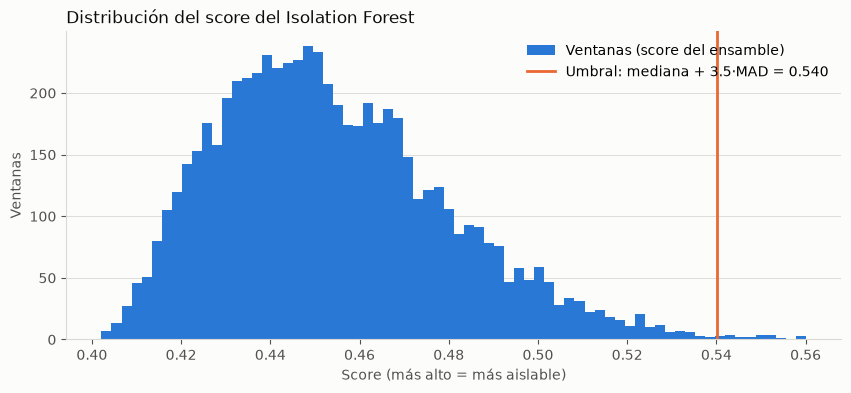

In [13]:
display(al.sensibilidad_umbral(score))

u_if = al.umbral_mad(score, K_UMBRAL)
fig, ax = plt.subplots(figsize=(10, 4)); fig.patch.set_facecolor(FONDO)
ax.hist(score, bins=70, color=AZUL, lw=0, label='Ventanas (score del ensamble)')
ax.axvline(u_if, color=NARANJA, lw=2, label=f'Umbral: mediana + {K_UMBRAL}·MAD = {u_if:.3f}')
estilo(ax, 'Distribución del score del Isolation Forest', 'Score (más alto = más aislable)', 'Ventanas')
ax.legend(frameon=False); plt.show()

In [14]:
mah = al.ajustar_mahalanobis(Z)
d2 = al.distancia_mahalanobis(Z, mah)
umbrales = al.fijar_umbrales(score.reindex(Z.index), d2, K_UMBRAL, Z_UNI)
det = al.detectar(score.reindex(Z.index), d2, Z, umbrales)

resumen = pd.DataFrame({
    'detector': ['Isolation Forest', 'Mahalanobis robusta', 'z univariado'],
    'ventanas': [int(det['D_IF'].sum()), int(det['D_MAH'].sum()), int(det['D_UNI'].sum())],
})
resumen['pct'] = (100 * resumen['ventanas'] / len(det)).round(2)
display(resumen)
print('Ventanas por nivel de consenso (cuántos detectores la marcan):', det['CONSENSO'].value_counts().sort_index().to_dict())

,detector,ventanas,pct
0,Isolation Forest,23,0.36
1,Mahalanobis robusta,1,0.02
2,z univariado,2,0.03


Ventanas por nivel de consenso (cuántos detectores la marcan): {0: 6308, 1: 26}


## 7. Validación sin verdad conocida: inyección sintética
No tenemos etiquetas, pero sí podemos **crear anomalías de tamaño conocido**: se toman ventanas reales, se desplaza una (o varias) features `m` desviaciones robustas y se mide qué fracción detecta el pipeline. La tabla responde: *¿qué tan grande debe ser un cambio en cada métrica para que lo veamos?*

- Es **potencia de detección**, no precisión. Dice qué cambios veríamos, pero no cuántas de las anomalías reales hay en los datos ni cuántas alarmas son falsas.
- Las inyecciones se puntúan con el modelo ya entrenado y con los mismos umbrales de las ventanas reales.
- "Un cambio de 4σ" se refiere a la desviación robusta de la feature en su hora del día. Las proporciones se acotan a [0, 1].

In [15]:
d2_inj = al.distancia_mahalanobis(Zi, mah)
det_inj = al.detectar(score_inj.reindex(Zi.index), d2_inj, Zi, umbrales)

orden = list(ESCENARIOS)
pot = {
    'Isolation Forest solo': al.potencia(inj, det_inj['D_IF'], orden),
    'Pipeline (>= 1 detector)': al.potencia(inj, det_inj['CONSENSO'] >= 1, orden),
}
sigma_min = pd.concat({k: al.magnitud_minima(v, OBJETIVO_RECALL) for k, v in pot.items()}, axis=1)
sigma_min.columns = [f'{c}: σ mínimo' for c in sigma_min.columns]
print(f'σ mínimo para detectar >= {int(OBJETIVO_RECALL * 100)} % de las inyecciones (NaN = no lo alcanza con {max(MAGNITUDES)}σ):')
display(sigma_min)

σ mínimo para detectar >= 80 % de las inyecciones (NaN = no lo alcanza con 8σ):


,Isolation Forest solo: σ mínimo,Pipeline (>= 1 detector): σ mínimo
_ESCENARIO,,
TOTAL_LLM_REQUESTS ↑,NaN,6.0
AVG_LLM_COST_USD ↑,NaN,6.0
RATIO_INJECTION ↑,NaN,6.0
AVG_TOKEN_RATIO ↑,NaN,6.0
AVG_RESPONSE_TIME_MS ↑,NaN,3.0
LLM_ERROR_RATE ↑,NaN,6.0
LLM_TIMEOUT_RATE ↑,NaN,4.0
TEMPERATURE_VARIANCE ↑,NaN,6.0
PROMPT_CATEGORY_ENTROPY ↓,NaN,6.0


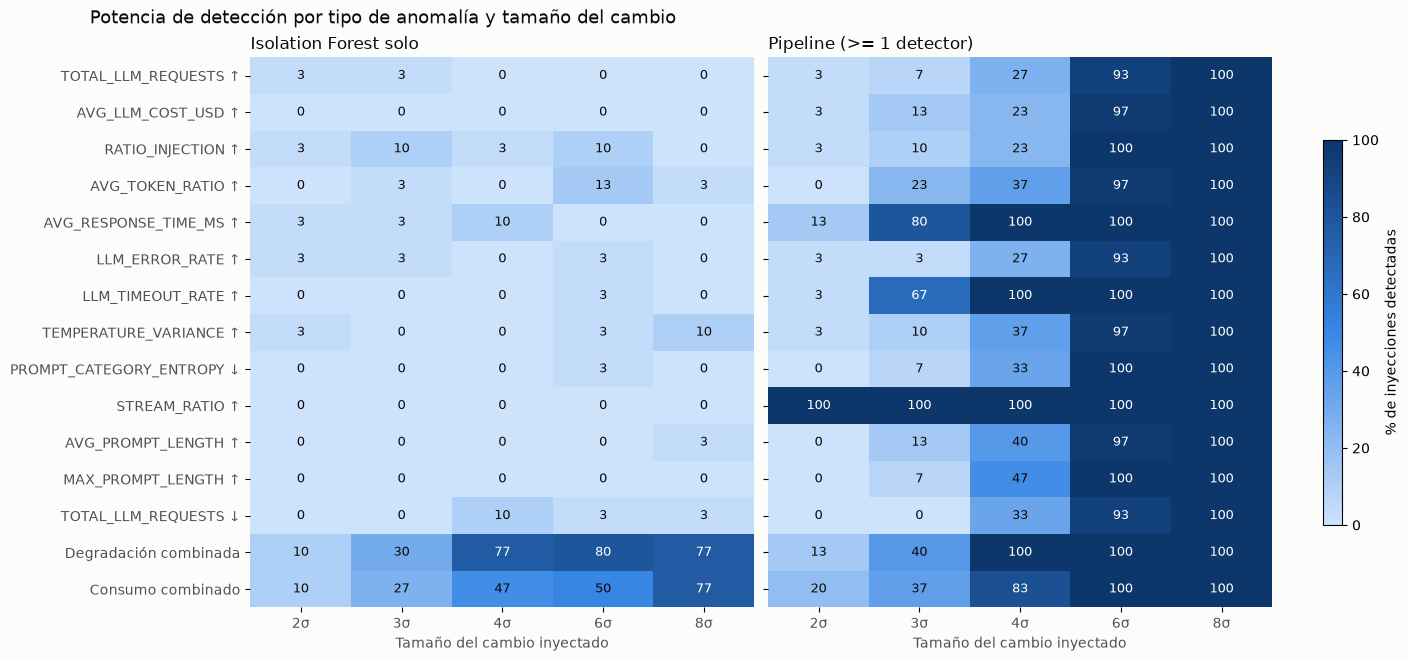

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(14, 6.5), sharey=True, constrained_layout=True); fig.patch.set_facecolor(FONDO)
for ax, (nombre, t) in zip(axs, pot.items()):
    im = ax.imshow(t.to_numpy() * 100, cmap=CMAP_SEC, vmin=0, vmax=100, aspect='auto')
    ax.set_xticks(range(len(t.columns)), [f'{m}σ' for m in t.columns], color=TINTA2)
    ax.set_yticks(range(len(t.index)), t.index, color=TINTA2)
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            v = t.iloc[i, j] * 100
            ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=9, color='white' if v > 55 else TINTA)
    ax.set_title(nombre, loc='left', fontsize=12, color=TINTA)
    ax.set_xlabel('Tamaño del cambio inyectado', color=TINTA2)
    for s in ax.spines.values(): s.set_visible(False)
fig.colorbar(im, ax=axs, shrink=0.7, label='% de inyecciones detectadas')
fig.suptitle('Potencia de detección por tipo de anomalía y tamaño del cambio', x=0.06, ha='left', fontsize=13, color=TINTA)
plt.show()

## 8. Interpretación de las ventanas anómalas
Para cada ventana marcada:
- **Explicación:** las features con mayor desviación (z robusta), su dirección (↑/↓), y el valor observado frente al típico de esa hora.
- **Tema:** seguridad, servicio, consumo, prompts, volumen, configuración o mezcla de temas, según qué features dominan. Si ninguna es extrema por sí sola, se rotula *multivariada*.

Luego las ventanas contiguas (a ≤ `MAX_GAP_MIN` minutos) se unen en **eventos**, con nivel:
- **alta:** al menos 2 detectores coinciden y el evento dura 2+ ventanas o una feature pasa de 6σ.
- **media:** 2+ detectores coinciden, o una feature pasa de 6σ.
- **baja:** lo marca un solo detector con desviación moderada. Es la candidata a ruido estadístico: conviene revisar solo si el tema es sensible (p. ej. seguridad).

In [17]:
marcada = det['CONSENSO'] >= 1
exp = al.explicar(win, Z, C, win.index[marcada])
w = win.join(det).join(exp)
eventos, vent_anom = al.agrupar_eventos(w, marcada, MAX_GAP_MIN)

print(f'{int(marcada.sum())} ventanas marcadas ({100 * marcada.mean():.2f} %) -> {len(eventos)} eventos')
print('Eventos por nivel:', eventos['NIVEL'].value_counts().to_dict())
pd.set_option('display.max_colwidth', 160)
display(eventos.drop(columns=['SCORE_PICO', 'CONSENSO_MAX']).head(25))

26 ventanas marcadas (0.41 %) -> 25 eventos
Eventos por nivel: {'baja': 25}


,EVENTO_ID,NIVEL,INICIO,FIN,DURACION_MIN,N_VENTANAS,Z_MAX,FAMILIA,LECTURA,VENTANA_PICO,EXPLICACION_PICO
0,6,baja,2026-10-02 20:55:00,2026-10-02 21:00:00,5.0,1,2.547869,multivariada,combinación inusual de varias métricas (ninguna es extrema por sí sola),2026-10-02 20:55:00,ninguna feature supera 3.0σ; la más alta: PROMPT_CATEGORY_ENTROPY (-2.5σ)
1,1,baja,2026-10-01 04:55:00,2026-10-01 05:00:00,5.0,1,4.416194,consumo,consumo atípico (costo o relación de tokens),2026-10-01 04:55:00,AVG_TOKEN_RATIO ↑ +4.4σ (1.917 vs 1.446)
2,19,baja,2026-10-10 08:15:00,2026-10-10 08:22:30,7.5,2,3.436798,servicio,"degradación del servicio (latencia, errores o timeouts)",2026-10-10 08:17:30,AVG_RESPONSE_TIME_MS ↑ +3.1σ (1.004e+04 vs 8777)
3,25,baja,2026-10-11 13:22:30,2026-10-11 13:27:30,5.0,1,2.811623,multivariada,combinación inusual de varias métricas (ninguna es extrema por sí sola),2026-10-11 13:22:30,ninguna feature supera 3.0σ; la más alta: PROMPT_CATEGORY_ENTROPY (-2.8σ)
4,7,baja,2026-10-02 21:47:30,2026-10-02 21:52:30,5.0,1,3.255889,consumo,consumo atípico (costo o relación de tokens),2026-10-02 21:47:30,AVG_TOKEN_RATIO ↑ +3.3σ (1.793 vs 1.446)
5,24,baja,2026-10-11 07:05:00,2026-10-11 07:10:00,5.0,1,2.911726,multivariada,combinación inusual de varias métricas (ninguna es extrema por sí sola),2026-10-11 07:05:00,ninguna feature supera 3.0σ; la más alta: AVG_PROMPT_LENGTH (+2.9σ)
6,8,baja,2026-10-03 12:27:30,2026-10-03 12:32:30,5.0,1,3.151209,seguridad,posible oleada de intentos de prompt injection (mensajes bloqueados),2026-10-03 12:27:30,RATIO_INJECTION ↑ +3.2σ (0.01139 vs 0.002008)
7,23,baja,2026-10-11 05:57:30,2026-10-11 06:02:30,5.0,1,4.137130,servicio,"degradación del servicio (latencia, errores o timeouts)",2026-10-11 05:57:30,AVG_RESPONSE_TIME_MS ↑ +4.1σ (1.046e+04 vs 8777)
8,9,baja,2026-10-03 13:50:00,2026-10-03 13:55:00,5.0,1,2.760033,multivariada,combinación inusual de varias métricas (ninguna es extrema por sí sola),2026-10-03 13:50:00,ninguna feature supera 3.0σ; la más alta: RATIO_INJECTION (+2.8σ)
9,16,baja,2026-10-08 06:57:30,2026-10-08 07:02:30,5.0,1,3.207416,mezcla de temas,cambio en la mezcla de categorías de prompt,2026-10-08 06:57:30,PROMPT_CATEGORY_ENTROPY ↓ -3.2σ (0.9488 vs 0.9712)


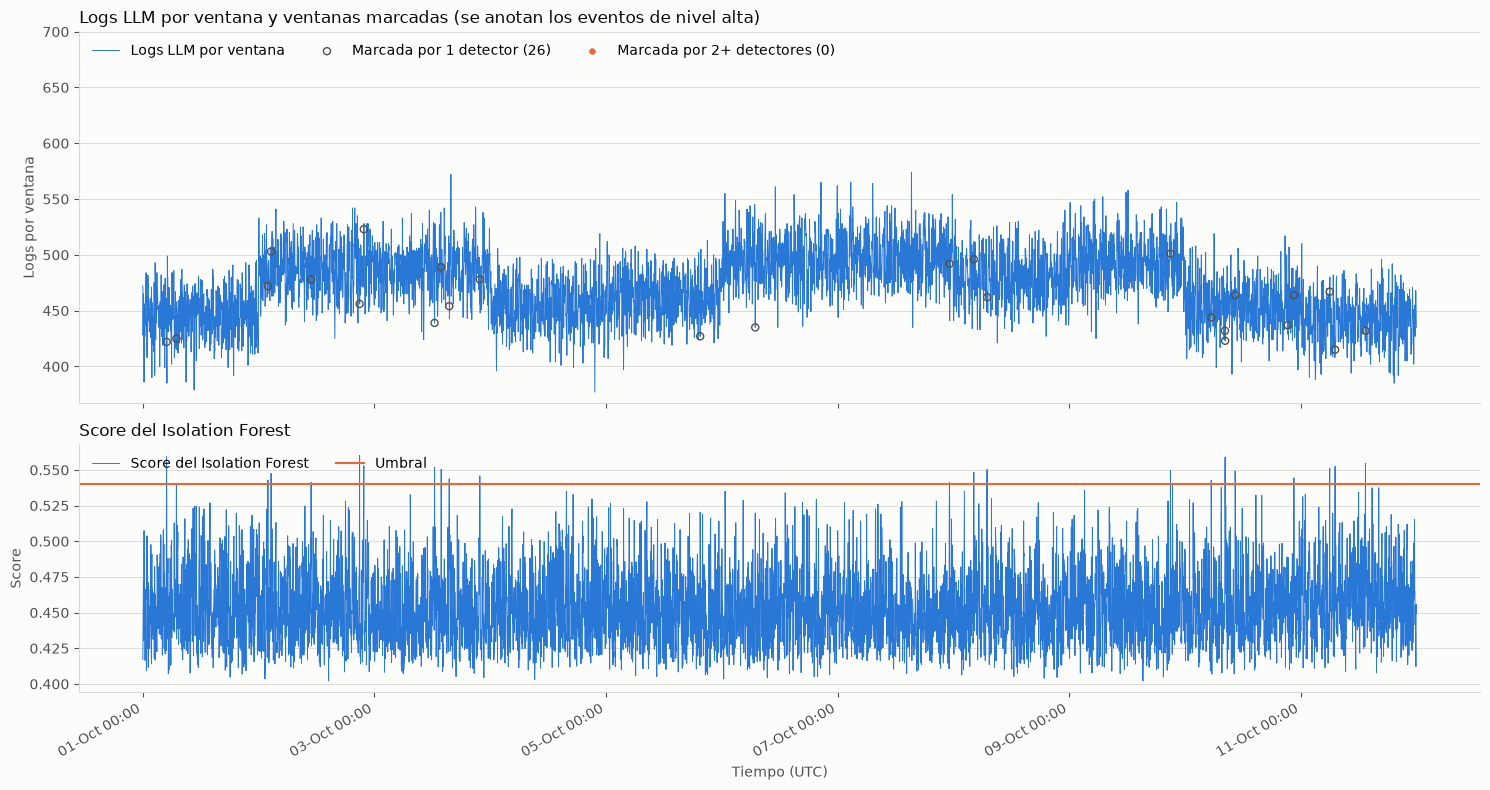

In [18]:
conf = w[w['CONSENSO'] >= 2]; solo = w[w['CONSENSO'] == 1]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(15, 8), sharex=True, gridspec_kw={'height_ratios': [3, 2]})
fig.patch.set_facecolor(FONDO)

a1.plot(w['WINDOW_START'], w['TOTAL_LLM_REQUESTS'], color=AZUL, lw=0.7, label='Logs LLM por ventana')
a1.scatter(solo['WINDOW_START'], solo['TOTAL_LLM_REQUESTS'], s=26, facecolors='none', edgecolors=TINTA2, lw=1.0,
           zorder=3, label=f'Marcada por 1 detector ({len(solo)})')
a1.scatter(conf['WINDOW_START'], conf['TOTAL_LLM_REQUESTS'], s=30, color=NARANJA, edgecolors=FONDO, lw=0.8,
           zorder=4, label=f'Marcada por 2+ detectores ({len(conf)})')
for _, e in eventos[eventos['NIVEL'] == 'alta'].head(8).iterrows():
    y = w.loc[w['WINDOW_START'] == e['VENTANA_PICO'], 'TOTAL_LLM_REQUESTS'].iloc[0]
    a1.annotate(f"{e['FAMILIA']}", (e['VENTANA_PICO'], y), xytext=(0, 26), textcoords='offset points',
                ha='center', fontsize=8, color=TINTA, bbox=dict(boxstyle='round,pad=0.2', fc=FONDO, ec=GRIS, lw=0.6),
                arrowprops=dict(arrowstyle='-', color=TINTA2, lw=0.6))
estilo(a1, 'Logs LLM por ventana y ventanas marcadas (se anotan los eventos de nivel alta)', ylabel='Logs por ventana')
a1.set_ylim(top=w['TOTAL_LLM_REQUESTS'].max() * 1.22)       # espacio arriba para leyenda y anotaciones
a1.legend(frameon=False, loc='upper left', ncol=3)

a2.plot(w['WINDOW_START'], w['SCORE_IF'], color=AZUL, lw=0.7, label='Score del Isolation Forest')
a2.axhline(umbrales['if'], color=NARANJA, lw=1.5, label='Umbral')
estilo(a2, 'Score del Isolation Forest', 'Tiempo (UTC)', 'Score')
a2.legend(frameon=False, loc='upper left', ncol=2)
a2.xaxis.set_major_formatter(mdates.DateFormatter('%d-%b %H:%M')); fig.autofmt_xdate()
fig.tight_layout(); plt.show()

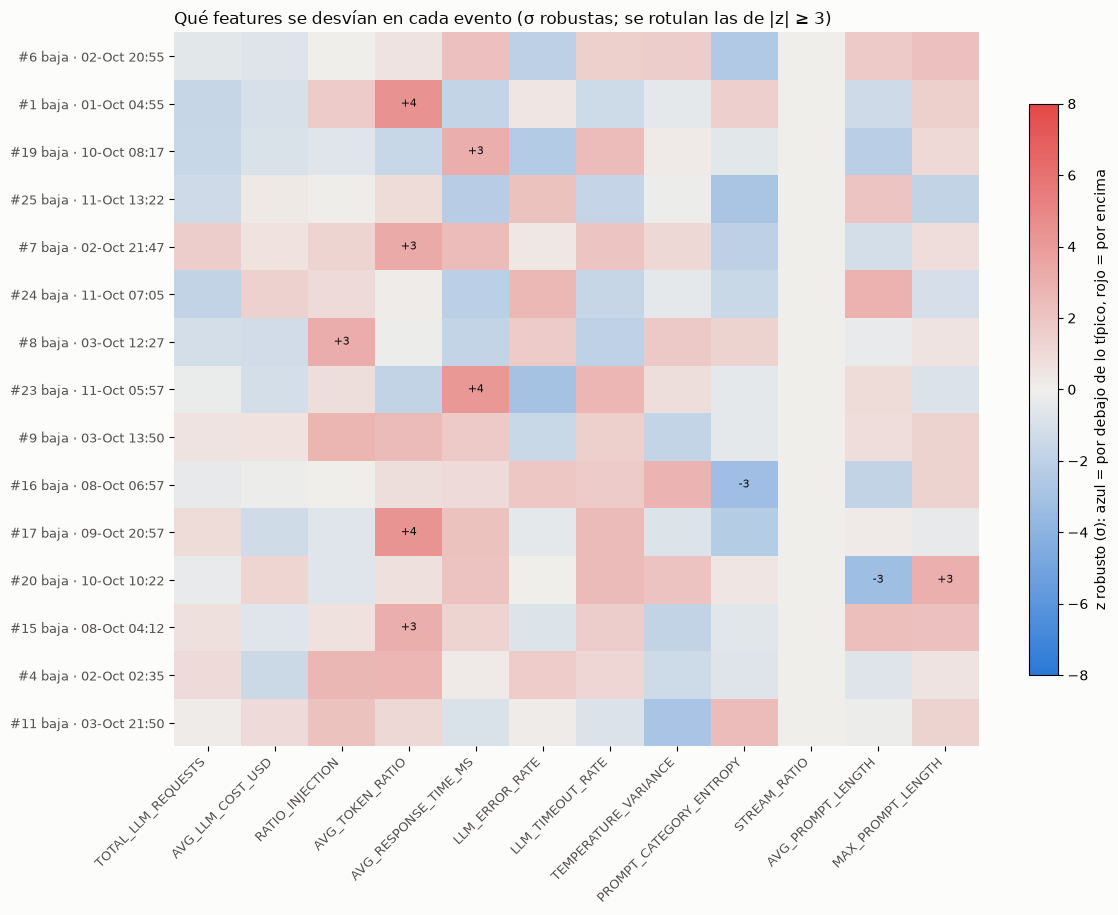

In [19]:
# Perfil de cada evento: z robusta de las 12 features en su ventana pico
pico_idx = vent_anom.groupby('EVENTO_ID')['SCORE_IF'].idxmax()
sel = eventos.head(15)
etiquetas = [f"#{r.EVENTO_ID} {r.NIVEL} · {r.VENTANA_PICO:%d-%b %H:%M}" for r in sel.itertuples()]
M_z = Z.loc[[pico_idx[i] for i in sel['EVENTO_ID']]].to_numpy()

fig, ax = plt.subplots(figsize=(12, 0.45 * len(sel) + 2.5)); fig.patch.set_facecolor(FONDO)
im = ax.imshow(M_z, cmap=CMAP_DIV, vmin=-8, vmax=8, aspect='auto')
ax.set_xticks(range(len(FEATURES_LLM)), FEATURES_LLM, rotation=45, ha='right', color=TINTA2, fontsize=9)
ax.set_yticks(range(len(sel)), etiquetas, color=TINTA2, fontsize=9)
for i in range(M_z.shape[0]):
    for j in range(M_z.shape[1]):
        if abs(M_z[i, j]) >= 3:
            ax.text(j, i, f'{M_z[i, j]:+.0f}', ha='center', va='center', fontsize=8,
                    color='white' if abs(M_z[i, j]) > 5.5 else TINTA)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title('Qué features se desvían en cada evento (σ robustas; se rotulan las de |z| ≥ 3)', loc='left', fontsize=12, color=TINTA)
fig.colorbar(im, ax=ax, shrink=0.8, label='z robusto (σ): azul = por debajo de lo típico, rojo = por encima')
fig.tight_layout(); plt.show()

### Opcional: explicación con valores Shapley de PAL
`show_explainer=True` hace que PAL devuelva, por ventana, cuánto aportó cada feature al score en `REASON_CODE`. Es una segunda opinión independiente de la z robusta de arriba. Está apagado por defecto porque recorre todas las ventanas; el formato exacto de `REASON_CODE` depende de la versión de `hana_ml`, así que se muestra tal cual.

In [20]:
VER_SHAP = False
if VER_SHAP:
    m_shap = IsolationForest(n_estimators=N_ARBOLES, max_samples=MAX_SAMPLES, random_state=SEMILLAS[0])
    m_shap.fit(data=z_h, key='WID', features=ZCOLS)
    r_shap = m_shap.predict(data=z_h, key='WID', features=ZCOLS, show_explainer=True,
                            explain_scope='outliers', top_k_attributions=5)
    display(r_shap.filter('LABEL = -1').head(10).collect())

## 9. Exportar

In [ ]:
ruta = Path('../data/ventanas_separadas/anomalias'); ruta.mkdir(parents=True, exist_ok=True)
w.join(Z.add_prefix('Z_')).assign(MARCADA=marcada).to_csv(ruta / 'llm_maria_ventanas.csv', index=False, encoding='utf-8-sig')
eventos.to_csv(ruta / 'llm_maria_eventos.csv', index=False, encoding='utf-8-sig')
sigma_min.to_csv(ruta / 'llm_maria_potencia_sigma_minimo.csv', encoding='utf-8-sig')
print(ruta.resolve())

## 10. Cómo leer los resultados y qué falta

**Lo que sí permite afirmar**
- Qué ventanas se desvían, en qué features, hacia dónde y cuánto (secciones 3 y 8).
- Que el ranking no depende de la semilla ni de entrenar y puntuar con los mismos datos (secciones 4 y 5).
- Qué tamaño de cambio en cada métrica detectaría el pipeline, y que el Isolation Forest solo no basta para cambios en una sola feature (sección 7).

**Lo que no permite afirmar**
- **Precisión ni recall reales.** La potencia por inyección mide la capacidad de detección ante cambios simulados; no se sabe cuántas anomalías reales hay ni cuántas alarmas son falsas. Para eso hace falta etiquetar una muestra a mano (p. ej. revisar los eventos de nivel alta y media y una muestra de los de nivel baja) o contar con la lista de inyecciones de quien generó los datos.
- Que una ventana marcada sea un ataque. Es una ventana inusual; la lectura de negocio es una hipótesis a confirmar.

**Limitaciones que persisten**
- Las features no incluyen el **contenido** del prompt, solo su longitud, y `RATIO_INJECTION` cuenta solo inyecciones ya bloqueadas. Anomalías que vivan en el texto no se ven. El siguiente paso natural es añadir features por familia de prompt (`prompt_families` en `ventanas_mejoras.py`).
- La línea base por hora usa pocos días (≈ 11). Si el ciclo semanal importa, harían falta más semanas.
- `K_UMBRAL`, `Z_UNI` y `MAX_GAP_MIN` siguen siendo decisiones de diseño; la sección 6 muestra su sensibilidad.
- La prueba de inyección usa desplazamientos en una o tres features. Anomalías con otra forma (p. ej. un tema que crece lentamente) pueden comportarse distinto.